# 04 - Remaining Useful Life (Random Forest regressor)

**Question:** *how many minutes of cutting before the tool reaches the 0.5 mm limit?*

This is the core of predictive maintenance: it tells **when** to plan the tool change,
so the tool is not changed too early (waste) or too late (scrap parts, breakage).

In [1]:
import sys, json
sys.path.append("..")  # to import features.py from the project root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from features import FEATURES, SIGNAL_FEATURES, WEAR_LIMIT_MM

In [2]:
df = pd.read_csv("../data/milling_features.csv")
print(len(df), "runs from", df["case"].nunique(), "tools")

166 runs from 16 tools


In [3]:
data = df.dropna(subset=["rul_min"])
X, y, tools = data[FEATURES], data["rul_min"], data["case"]
print(len(data), "runs from", tools.nunique(), "tools that reached the limit")

122 runs from 13 tools that reached the limit


## Honest evaluation: leave-one-tool-out

The runs of one tool are strongly linked to each other. A random split would put runs of the same tool
in train **and** test, and the score would look much better than reality.
Here the model is always tested on **tools it has never seen** (`GroupKFold` grouped by `case`).

In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error

model = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)
predicted = cross_val_predict(model, X, y, groups=tools, cv=GroupKFold(n_splits=tools.nunique()))

mae = mean_absolute_error(y, predicted)
baseline_mae = mean_absolute_error(y, np.full(len(y), y.mean()))
print(f"MAE: {mae:.1f} min   (always guessing the average: {baseline_mae:.1f} min)")

MAE: 8.0 min   (always guessing the average: 18.3 min)


Prediction vs truth for a few unseen tools. The estimate gets better as the end of life gets closer,
which is exactly when it matters.

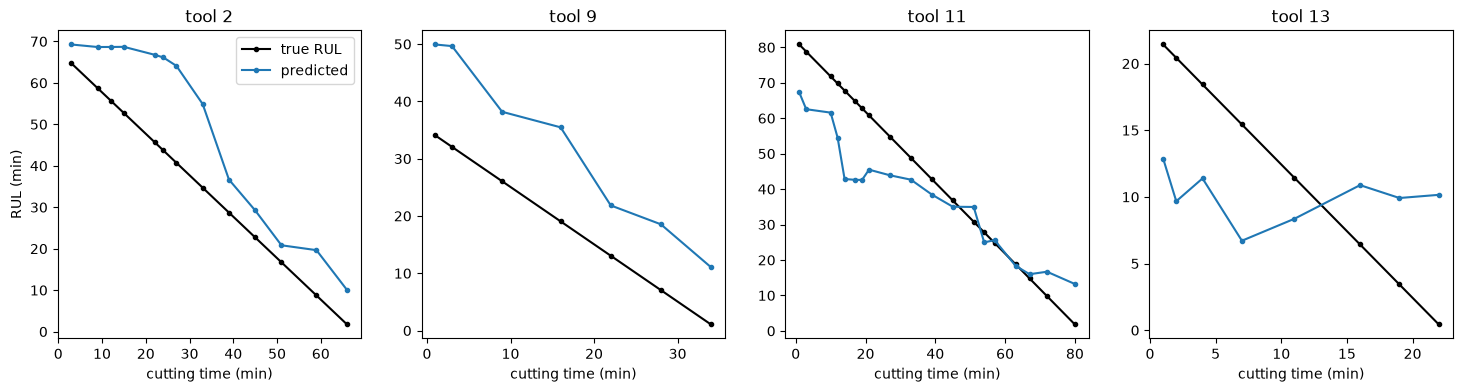

In [5]:
data = data.assign(predicted=predicted)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, case in zip(axes, [2, 9, 11, 13]):
    tool = data[data["case"] == case]
    ax.plot(tool["cut_time"], tool["rul_min"], "k-o", ms=3, label="true RUL")
    ax.plot(tool["cut_time"], tool["predicted"], "-o", ms=3, label="predicted")
    ax.set_title(f"tool {case}"); ax.set_xlabel("cutting time (min)")
axes[0].set_ylabel("RUL (min)"); axes[0].legend();

Error when the tool is close to its end (RUL < 15 min):

In [6]:
close = data["rul_min"] < 15
print(f"MAE when RUL < 15 min: {mean_absolute_error(data.loc[close, 'rul_min'], data.loc[close, 'predicted']):.1f} min")

MAE when RUL < 15 min: 5.4 min


## Train on all tools and save

In [7]:
model.fit(X, y)
metrics = {"name": "Random Forest regressor", "task": "Remaining Useful Life (min)",
           "score": f"MAE {mae:.1f} min on unseen tools (baseline {baseline_mae:.1f})"}
joblib.dump(model, "../models/rul_predictor.joblib")
json.dump(metrics, open("../models/rul_predictor_metrics.json", "w"), indent=2)
metrics

{'name': 'Random Forest regressor',
 'task': 'Remaining Useful Life (min)',
 'score': 'MAE 8.0 min on unseen tools (baseline 18.3)'}